# TP3: Noise Spectrum Density Estimation and Wiener Filtering
## Autor: Volodya ALEKSANYAN

**Goal**: Estimate the spectrum density of 3 noies files and identify the "color". Simulate different noisy version of a signal. Denoise the signal using the Wiener filter.

Course:

Let $X$ be a random signal. The Fourier transform of $X$ is not meaningful. The spectrum of a random signl is the Fourier transform of its autocorrelation function:
$$S(\nu) = \hat{R}_x[\nu]$$
It can be difficult to estimare in practice. We use 2 estimators:
- Periodogram estimator (power spectrum of the observed tajectory $x$)
- Welch estimator (average of short-time power spectrum)

### Noise
A we call a Gaussian white noise if all the random variables $X[n]$ are iid from $\mathcal{N}(0, \sigma^2)$, the Autocorrelation function is $R_x[t] = \sigma^2 \delta[t]$ and the spectrum is $S(\nu) = \sigma^2$ (flat spectrum). 

A Gaussian colored noise is a filtered white noise

### Linear Denoising
Let $y$ be a noisy measure of a "clean" signal $x$, corrupted by some additive noise $n$:
$$y = x + n$$
The Signal to Noise Ratio (SNR) is defined as:
$$SNR(y|x) = 20 \log\left(\frac{||x||}{||y-x||}\right)$$
Goal : to find the best (oracle) filter $h$  such that $x_{est} = h * y$ is the best estimate of $x$. 

Solution: Wiener filter, given in the frequency domain by:

$$\hat{h}(\nu) = \frac{E[|\hat{x}(\nu)|^2]}{E[|\hat{x}(\nu)|^2] + E[|\hat{n}(\nu)|^2]}$$

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from scipy.io import wavfile
from scipy import signal
from scipy.ndimage import uniform_filter

It's just a copy from other lab works

In [3]:
# Utils
def load_wav(path):
    """Load a wav file as float in [-1, 1], with the mean removed."""
    fs, x = wavfile.read(path)
    x = x.astype(float) / 32768
    return fs, x - x.mean()

def load_image(path, gray=True):
    """Load an image as float in [0, 1]"""
    img = mpimg.imread(path).astype(float)
    if img.max() > 1:
        img /= 255
    if img.ndim == 3 and img.shape[2] == 4:      # drop alpha chanel
        img = img[..., :3]
    if gray and img.ndim == 3:
        img = img.mean(axis=2)
    return img

def db(P):
    return 10 * np.log10(P)

def show(images, titles, cmap='gray', figsize=None, vmin=0, vmax=1, cols=None, panel_size=6):
    """Display images in a grid. `cols` caps how many go in one row (default: all in one row)."""
    n = len(images)
    cols = cols or n
    rows = int(np.ceil(n / cols))
    fig, ax = plt.subplots(rows, cols, figsize=figsize or (panel_size * cols, panel_size * rows))
    ax = np.atleast_1d(ax).flatten()
    for a, im, ti in zip(ax, images, titles):
        a.imshow(im, cmap=cmap, vmin=vmin, vmax=vmax)
        a.set_title(ti)
        a.axis('off')
    for a in ax[n:]:                 # hide unused panels when the grid isn't full
        a.axis('off')
    plt.tight_layout()
    plt.show()

## Noise spectrum density estimation

### The two estimateurs

- Periodogram is the modulus in square of the FT of the whole file, $\frac{1}{N}|\hat{x}(\nu)|^2$. Welch filter cut the recording in short overlapping segemnts, computes the periodogram of each piece and average them.

Both are written by hand below, then checked against scipy to see if it is occrect.

Our signal is a real valued, so we can just keep the positive frequencies.

In [4]:
def positive_only(P, n):
    """We keep only the positive frequencies. 
    I have took scipy convention for doubling everything from index 1 then halve the last value if n is pair"""
    P[..., 1:] *= 2
    if n % 2 == 0:
        P[..., -1] /= 2
    return P

def periodogram(x, fs):
    N = len(x)
    P = np.abs(np.fft.rfft(x))**2 / (fs * N)
    
    return np.fft.rfftfreq(N, 1 / fs), positive_only(P, N)

def Welch_filter(x, fs, nperseg=2048):
    w = signal.get_window('hann', nperseg)
    starts = range(0, len(x) - nperseg + 1, nperseg // 2)           # 50% overlap
    pieces = np.array([x[s:s + nperseg] * w for s in starts])

    P = (np.abs(np.fft.rfft(pieces, axis=1))**2).mean(axis=0) / (fs * (w**2).sum())
    
    return np.fft.rfftfreq(nperseg, 1 / fs), positive_only(P, nperseg)

In [5]:
names = ["noise1", "noise2", "noise3"]
noises = {}

for name in names:
    fs, noises[name] = load_wav(f'../data/{name}.wav')
    x = noises[name]
    print(f'{name}: fs={fs}Hz, len: {len(x) / fs:.2f}s, std={x.std():.3f}')

# check against scipy
x = noises["noise1"]
print('Periodogram, max relative diff with scipy:', np.abs(periodogram(x, fs)[1] / signal.periodogram(x, fs, detrend=False)[1] - 1)[1:].max())
print('Welch,       max relative diff with scipy:', np.abs(Welch_filter(x, fs)[1] / signal.welch(x, fs, nperseg=2048, detrend=False)[1] - 1)[1:].max())

noise1: fs=16000Hz, len: 8.75s, std=0.214
noise2: fs=16000Hz, len: 8.75s, std=0.229
noise3: fs=16000Hz, len: 8.75s, std=0.213
Periodogram, max relative diff with scipy: 2.7977620220553945e-13
Welch,       max relative diff with scipy: 2.55351295663786e-15


The Max difference between scipy is 2e-13 in worst case, so we can conisder it to be nearly identical in performance. 

### Periodogram vs Welch on the three noises
 
/!\ The frequency axis is logarithmic and the density is in dB, so a power law $1/f^\alpha$ appears as a line.

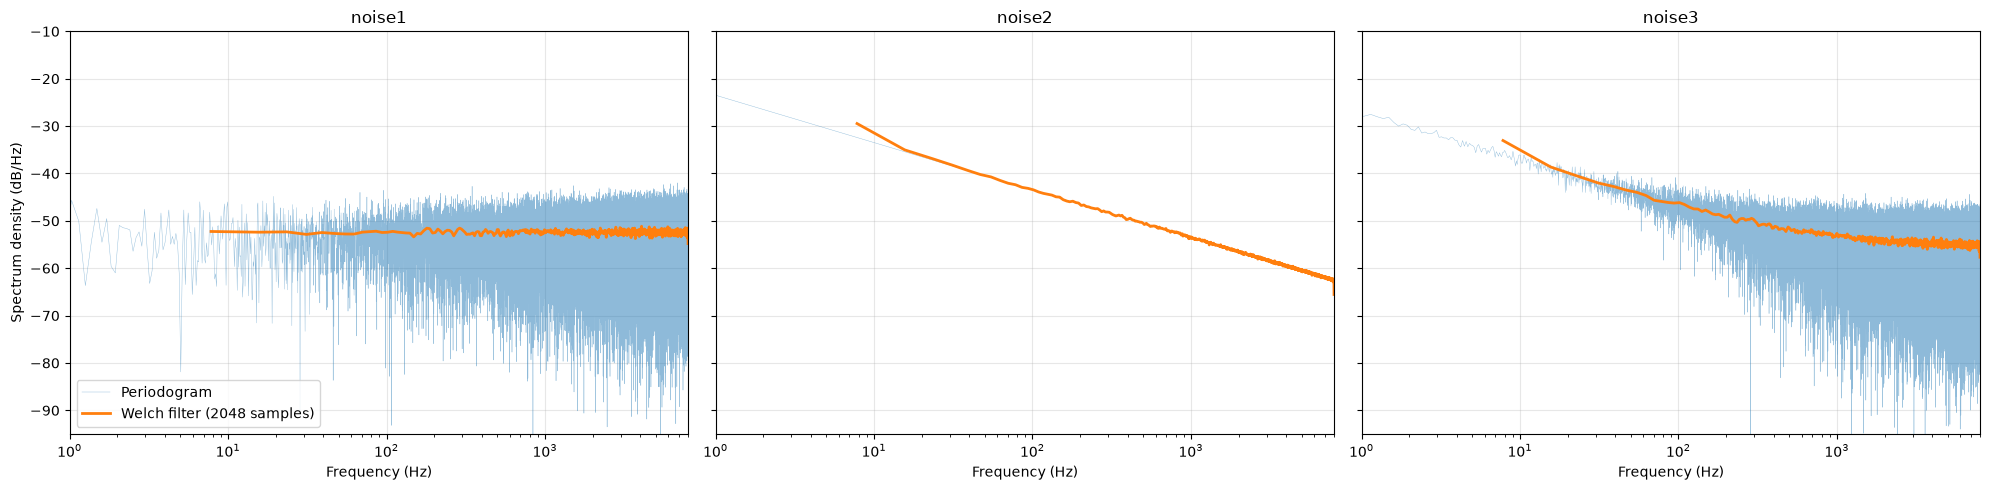

noise1: fluctuation around the trend: periodogram  5.54 dB, Welch 0.38 dB
noise2: fluctuation around the trend: periodogram  0.00 dB, Welch 0.12 dB
noise3: fluctuation around the trend: periodogram  5.55 dB, Welch 0.40 dB


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5), sharey=True)

for a, name in zip(ax, names):
    fp, Pp = periodogram(noises[name], fs)
    fw, Pw = Welch_filter(noises[name], fs)
    a.semilogx(fp[1:], db(Pp[1:]), lw=0.3, color='tab:blue', alpha=0.5, label='Periodogram')
    a.semilogx(fw[1:], db(Pw[1:]), lw=2, color='tab:orange', label='Welch filter (2048 samples)')
    a.set_title(name)
    a.set_xlabel('Frequency (Hz)')
    a.set_xlim(1, fs / 2)
    a.set_ylim(-95, -10)
    a.grid(alpha=0.3)
ax[0].set_ylabel('Spectrum density (dB/Hz)')
ax[0].legend(loc='lower left')
plt.tight_layout()
plt.show()

# how much each estimate moves around its own trend, between 1 and 7 kHz
for name in names:
    fp, Pp = periodogram(noises[name], fs)
    fw, Pw = Welch_filter(noises[name], fs)
    scatter = []
    for f, P in [(fp, Pp), (fw, Pw)]:
        m = (f > 1000) & (f < 7000)
        trend = np.polyval(np.polyfit(np.log10(f[m]), db(P[m]), 1), np.log10(f[m]))
        scatter.append((db(P[m]) - trend).std())
    print(f'{name}: fluctuation around the trend: periodogram {scatter[0]:5.2f} dB, Welch {scatter[1]:4.2f} dB')

- The periodogram follows the right level on average, but it is very irregular as we can see in plots.About 5.5dB around the general trend for the noise1 and noise3.
- Welch in other hand averages 135 pieces (in our case), so the fluctuation drops to about 0.4 dB and the shape of the spectrum becomes **much more** readable. The problem that we get is a coarser frequency axis as we only have one point every 7.8 Hz, so the lowest frequencies are not even seen.

I would like to talk about noise2 especially. It's a special case as its periodogram is already a perfect line with 0dB of fluctuation. A random recording cannot do that and I think that it was probably built in the Fourier domain.

### Welch

The only parameter of Welch is the length of the pieces. We try three values on noise3.

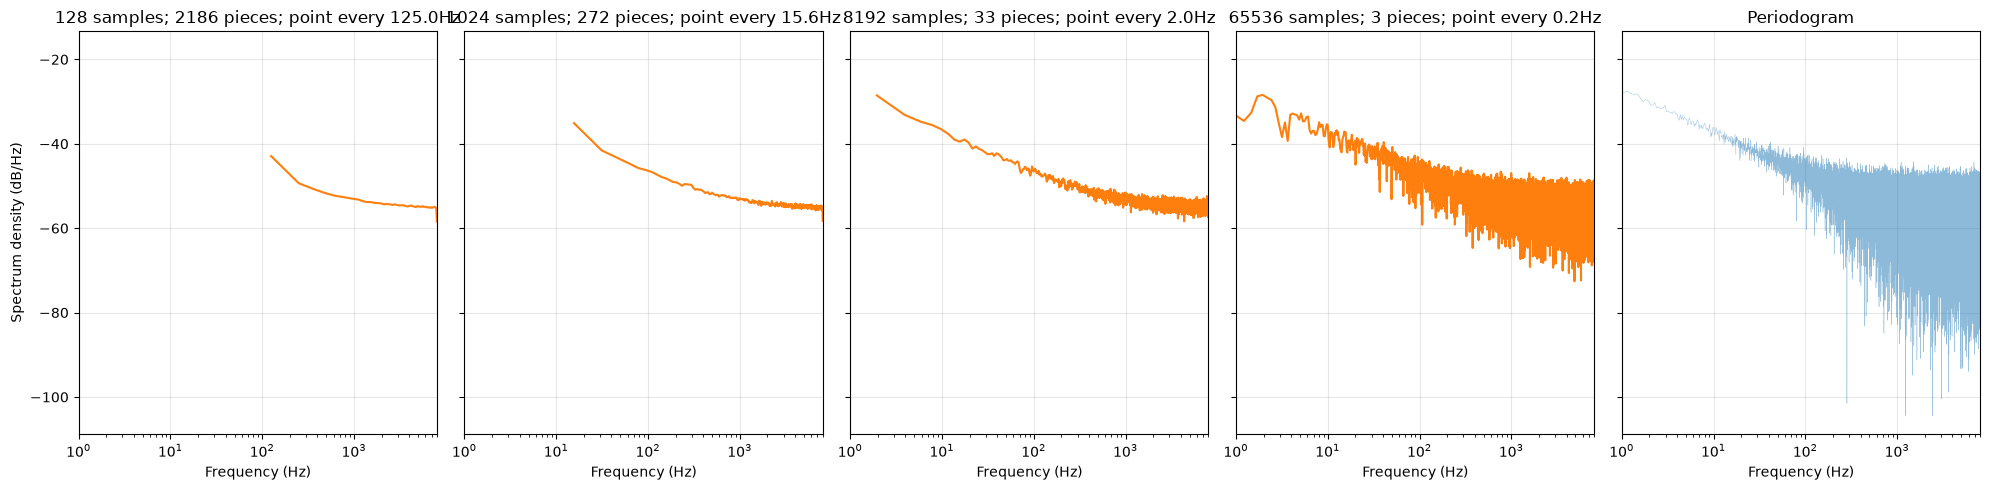

In [7]:
N = [2**k for k in range(7, 17, 3)]
fig, ax = plt.subplots(1, len(N)+1, figsize=(20, 5), sharey=True)

for a, n in zip(ax, N):
    f, P = Welch_filter(noises['noise3'], fs, n)
    n_pieces = (len(noises['noise3']) - n) // (n // 2) + 1
    a.semilogx(f[1:], db(P[1:]), color='tab:orange')
    a.set_title(f'{n} samples; {n_pieces} pieces; point every {fs / n:.1f}Hz')
    a.set_xlabel('Frequency (Hz)')
    a.set_xlim(1, fs / 2)
    a.grid(alpha=0.3)

# Periodogram for comparison
fp, Pp = periodogram(noises['noise3'], fs)
ax[-1].semilogx(fp[1:], db(Pp[1:]), lw=0.3, color='tab:blue', alpha=0.5, label='Periodogram')
ax[-1].set_title('Periodogram')
ax[-1].set_xlabel('Frequency (Hz)')
ax[-1].set_xlim(1, fs / 2)
ax[-1].grid(alpha=0.3)


ax[0].set_ylabel('Spectrum density (dB/Hz)')
plt.tight_layout()
plt.show()

- Short pieces (128) gives many pieces to average, so the curve is very smooth, but there is only one point every 125 Hz and all the low-frequency part is lost.
- Long pieces (65536), in the other hand, allow us to see down to 0.2 Hz, but only 3 pieces are averaged and the curve is irregular again, closer to a periodogram.

We keep an intermediate length: 2048 by default, and 8192 below, where we need more low frequencies to measure the slopes.

### Colour of the noises

The colour is given by how the density changes with frequency. On our log/dB plot, it is when the frequency is multiplied by 10:

| Colour | Density | Slope |
|---|---|---|
| White | constant | 0 dB/decade |
| Pink | $1/f$ | $-10$ dB/decade |
| Brown | $1/f^2$ | $-20$ dB/decade |
| Blue | $f$ | $+10$ dB/decade |

We fit this slope on the Welch estimate, separately on low and high frequencies.

	20-200 Hz   200-2000 Hz   2000-7000 Hz   (dB/decade)
noise1:      0.2          0.0           0.1
noise2:    -10.2        -10.0         -10.0
noise3:     -9.1         -4.7          -1.6


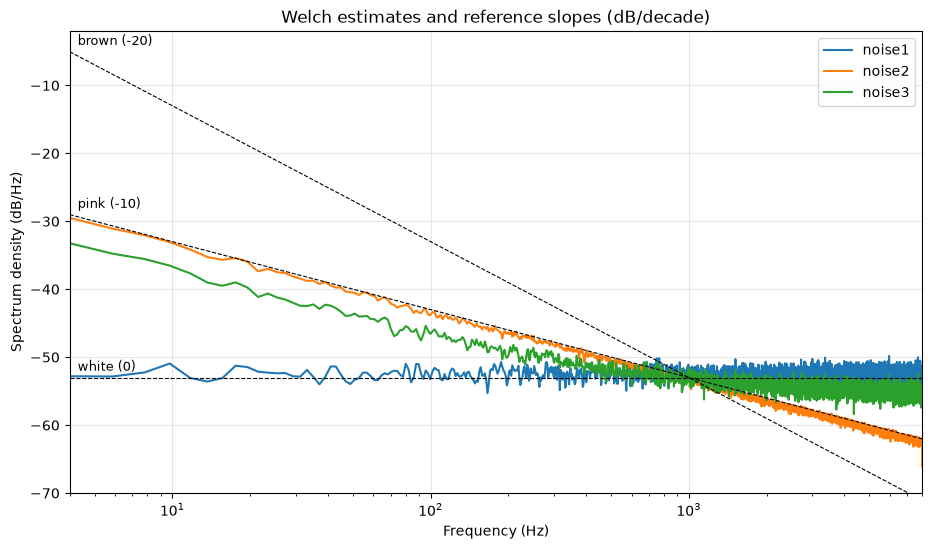

In [8]:
def slope(f, P, fmin, fmax):
    """Slope of the density in dB per decade between fmin and fmax."""
    m = (f >= fmin) & (f <= fmax)
    return np.polyfit(np.log10(f[m]), db(P[m]), 1)[0]

welch_est = {name: Welch_filter(noises[name], fs, 8192) for name in names}

print("\t20-200 Hz   200-2000 Hz   2000-7000 Hz   (dB/decade)")
for name in names:
    f, P = welch_est[name]
    print(f'{name}:  {slope(f, P, 20, 200):7.1f}   {slope(f, P, 200, 2000):10.1f}   {slope(f, P, 2000, 7000):11.1f}')

plt.figure(figsize=(11, 6))
for name in names:
    f, P = welch_est[name]
    plt.semilogx(f[1:], db(P[1:]), lw=1.5, label=name)
# reference slopes, all crossing at 1 kHz
fr = np.array([4, fs / 2])
for s, label in [(0, 'white (0)'), (-10, 'pink (-10)'), (-20, 'brown (-20)')]:
    plt.semilogx(fr, -53 + s * np.log10(fr / 1000), 'k--', lw=0.8)
    plt.text(4.3, -53 + s * np.log10(4 / 1000) + 1, label, fontsize=9)
plt.xlim(4, fs / 2)
plt.ylim(-70, -2)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Spectrum density (dB/Hz)')
plt.title('Welch estimates and reference slopes (dB/decade)')
plt.legend(loc='upper right')
plt.grid(alpha=0.3)
plt.show()

- **noise1**: the slope is 0 everywhere, the density is flat. We confirm that it is a **white noise**.
- **noise2**: $-10$ dB/decade on the whole range, it follows the pink reference line (nearly perfectly). It is a **pink noise** ($1/f$), when the frequency is multiplied by 10, the power is divided by 10.
- **noise3**: there is not one slope. It is about $-9$ dB/decade at low frequencies (pink), then the curve flattens to $-1.6$ dB/decade at high frequencies (almost white). It is not a single colour but a **mixture of pink and white**.

None of them is brown ($-20$) or blue (rising).

### Is noise3 actually a mixture of the two others?

noise3 looks like pink + white as we said earlier multiple times. Thus, we have to test it. We look for the best $a, b$ such that $\text{noise3} \approx a \cdot \text{noise1} + b \cdot \text{noise2}$ (least squares on the samples).

In [9]:
x1, x2, x3 = (noises[n] for n in names)
(a, b), *_ = np.linalg.lstsq(np.c_[x1, x2], x3, rcond=None)
err = np.linalg.norm(a * x1 + b * x2 - x3) / np.linalg.norm(x3)

In [10]:
print(f'noise3 = {a:.3f} * noise1 + {b:.3f} * noise2   (relative error: {err:.1e})')
print(f'correlation between noise1 and noise2: {np.corrcoef(x1, x2)[0, 1]:.3f}')

noise3 = 0.705 * noise1 + 0.659 * noise2   (relative error: 5.7e-05)
correlation between noise1 and noise2: -0.005


In [11]:
f, P3 = Welch_filter(x3, fs)
white_part, pink_part = a**2 * Welch_filter(x1, fs)[1], b**2 * Welch_filter(x2, fs)[1]
m = (f > 50) & (f < 7000)
f_cross = (pink_part[m] * f[m]).mean() / white_part[m].mean()       # white part = level, pink part = c / f
print(f'pink part = white part around {f_cross:.0f} Hz')

pink part = white part around 682 Hz


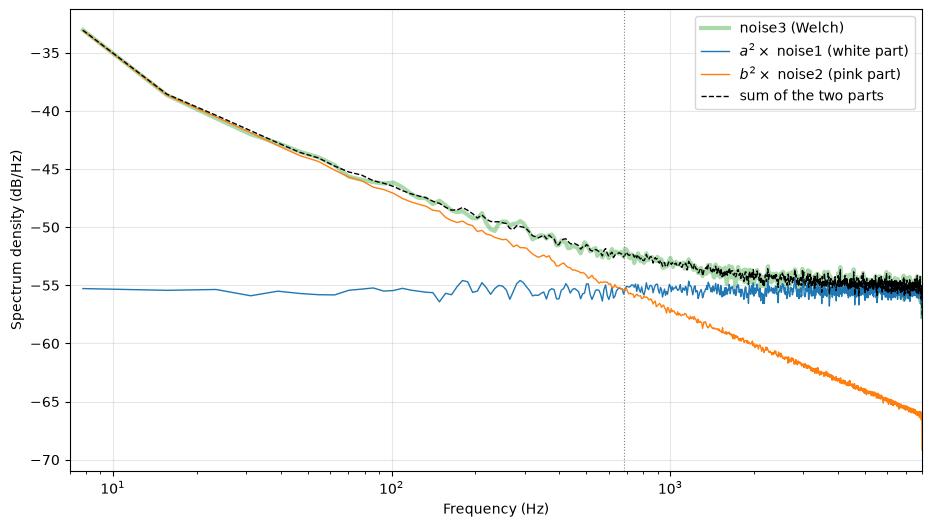

In [12]:
plt.figure(figsize=(11, 6))
plt.semilogx(f[1:], db(P3[1:]), lw=3, color='tab:green', alpha=0.4, label='noise3 (Welch)')
plt.semilogx(f[1:], db(white_part[1:]), lw=1, color='tab:blue', label=r'$a^2 \times$ noise1 (white part)')
plt.semilogx(f[1:], db(pink_part[1:]), lw=1, color='tab:orange', label=r'$b^2 \times$ noise2 (pink part)')
plt.semilogx(f[1:], db((white_part + pink_part)[1:]), 'k--', lw=1, label='sum of the two parts')
plt.axvline(f_cross, color='gray', lw=0.8, ls=':')
plt.xlim(7, fs / 2)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Spectrum density (dB/Hz)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

noise3 is actually $0.705\text{noise1} + 0.659\text{noise2}$.

## Wiener denoising of an image
### Noisy images at a chosen SNR

For a white Gaussian noise of sd $\sigma$ on $N$ pixels, $||n|| \approx \sigma\sqrt{N}$. From the definition of the SNR given in the course, we have:

$$\sigma = \frac{||x||}{\sqrt{N}} \, 10^{-SNR(y|x)/20}$$

In [13]:
def snr(x, y):
    return 20 * np.log10(np.linalg.norm(x) / np.linalg.norm(x - y))

def add_noise(x, snr_db, seed=0):
    """Add a white Gaussian noise so that SNR(y|x) = snr_db. Returns the noisy image and sigma."""
    sigma = np.linalg.norm(x) / np.sqrt(x.size) * 10**(-snr_db / 20)
    return x + sigma * np.random.default_rng(seed).standard_normal(x.shape), sigma

In [14]:
x0 = load_image('../data/barbara.jpg')
N = x0.size

target  0 dB: sigma = 0.475, measured SNR = -0.01 dB
target  5 dB: sigma = 0.267, measured SNR = 4.99 dB
target 10 dB: sigma = 0.150, measured SNR = 9.99 dB
target 15 dB: sigma = 0.084, measured SNR = 14.99 dB
target 20 dB: sigma = 0.047, measured SNR = 19.99 dB


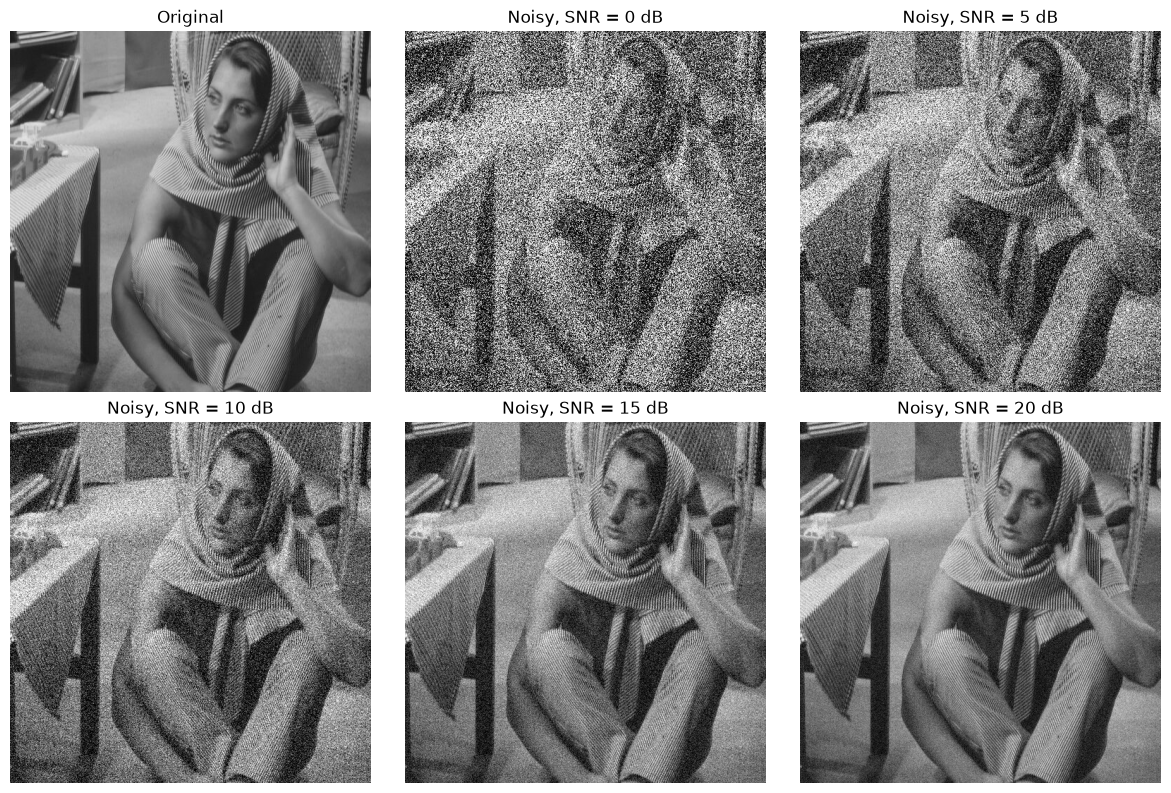

In [15]:
snrs = [0, 5, 10, 15, 20]
noisy, sigmas = {}, {}
for s in snrs:
    noisy[s], sigmas[s] = add_noise(x0, s)
    print(f'target {s:2d} dB: sigma = {sigmas[s]:.3f}, measured SNR = {snr(x0, noisy[s]):.2f} dB')

show([x0] + [noisy[s] for s in snrs], ['Original'] + [f'Noisy, SNR = {s} dB' for s in snrs], cols=3, panel_size=4)

### The Wiener filter

The filter needs two things:
- the **noise** spectra: it's white, so its spectrum is flat and $E[|\hat{n}(\nu)|^2] = N\sigma^2$ for every frequency;
- the **image**: we do not know it in practice... Like in the Numerical Tour, we first use the spectrum $|\hat{x}(\nu)|^2$ of the clean image (*l'oracle*). This gives the best result a linear filter can reach.

$$\hat{h}(\nu) = \frac{|\hat{x}(\nu)|^2}{|\hat{x}(\nu)|^2 + N\sigma^2}$$

The filter is a gain between 0 and 1 for each frequency. Close to 1 where the image is stronger than the noise, close to 0 where the noise is stronger.

In [16]:
def wiener(y, Px, sigma):
    """Wiener filter for a white noise of std sigma, Px = power spectrum of the signal. Returns (estimate, filter)."""
    H = Px / (Px + y.size * sigma**2)
    return np.real(np.fft.ifft2(H * np.fft.fft2(y))), H

def radial_profile(P):
    """Average of a 2D spectrum over all directions, as a function of the distance to the zero frequency."""
    n1, n2 = P.shape
    fy, fx = np.fft.fftfreq(n1)[:, None], np.fft.fftfreq(n2)[None, :]
    k = np.round(np.hypot(fx, fy) * n1).astype(int)
    prof = np.bincount(k.ravel(), P.ravel()) / np.bincount(k.ravel())
    return np.arange(n1 // 2) / n1, prof[:n1 // 2]

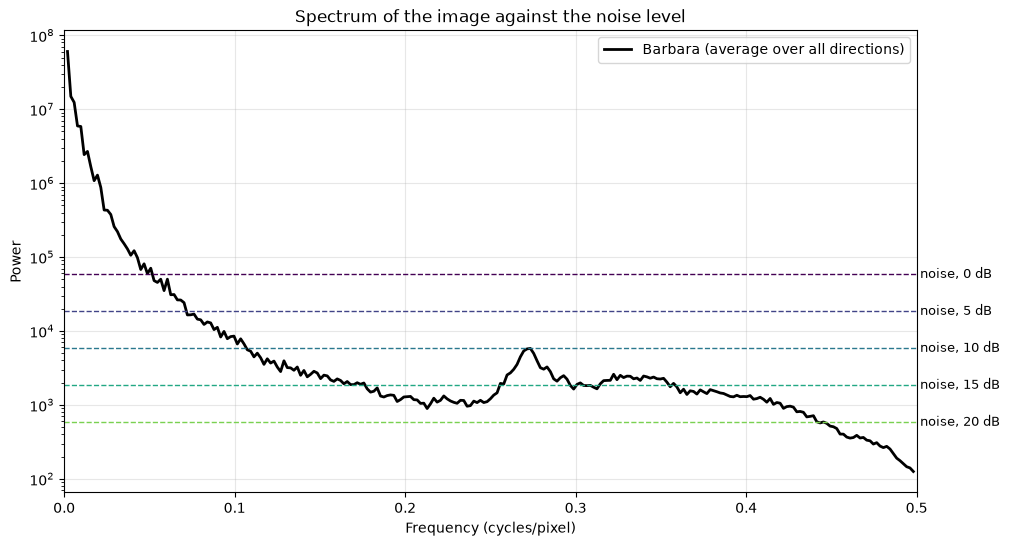

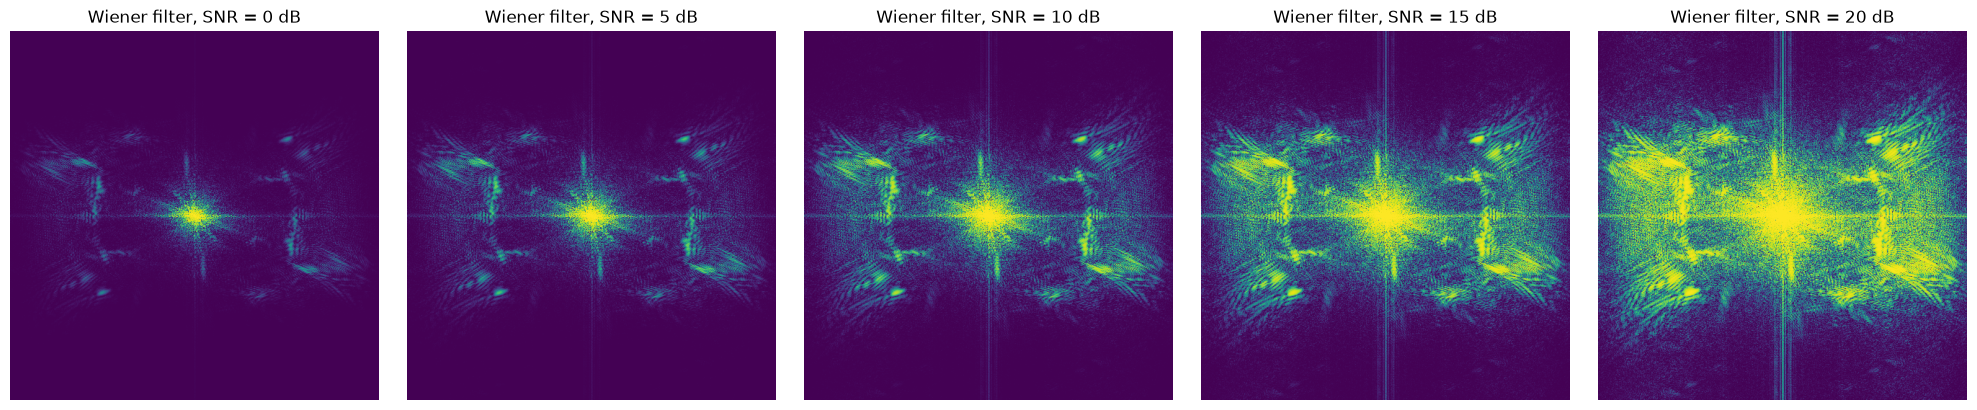

In [17]:

Px = np.abs(np.fft.fft2(x0))**2
denoised, filters = {}, {}
for s in snrs:
    denoised[s], filters[s] = wiener(noisy[s], Px, sigmas[s])

# image spectrum vs noise levels
fr, prof = radial_profile(Px)
plt.figure(figsize=(11, 6))
plt.semilogy(fr[1:], prof[1:], 'k', lw=2, label='Barbara (average over all directions)')
for s in snrs:
    plt.axhline(N * sigmas[s]**2, lw=1, ls='--', color=plt.cm.viridis(s / 25))
    plt.text(0.502, N * sigmas[s]**2, f'noise, {s} dB', va='center', fontsize=9)
plt.xlim(0, 0.5)
plt.xlabel('Frequency (cycles/pixel)')
plt.ylabel('Power')
plt.title('Spectrum of the image against the noise level')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

show([np.fft.fftshift(filters[s]) for s in snrs], [f'Wiener filter, SNR = {s} dB' for s in snrs], cmap='viridis', panel_size=4)

The image has most of its strength in the low frequencies, while the noise has the same level everywhere. The filter keeps the frequencies where the black curve is above the noise line and removes the others.

- The more noise, the smaller the bright area. In fact, at 0 dB, only the very low frequencies are kept, and at 20 dB almost everything is kept.
- The bright spots far from the centre are the stripes of the clothes, as it's a strong pattern at a precise frequency, so it stays above the noise.

### Resultats

SNR noisy	SNR Wiener	gain
  -0.0 dB	  15.9 dB	+15.9 dB
   5.0 dB	  17.4 dB	+12.4 dB
  10.0 dB	  19.4 dB	 +9.4 dB
  15.0 dB	  21.9 dB	 +6.9 dB
  20.0 dB	  24.9 dB	 +4.9 dB


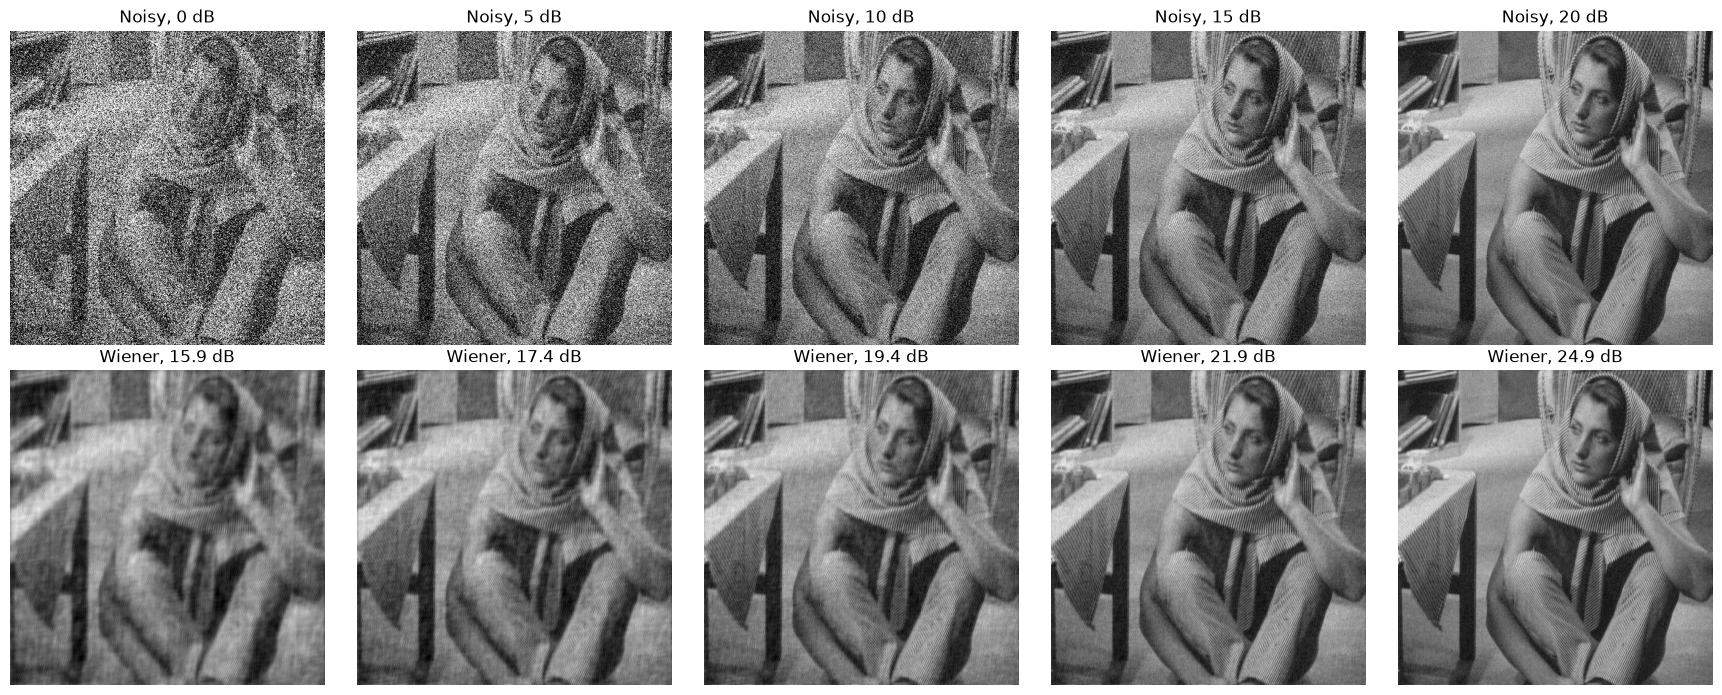

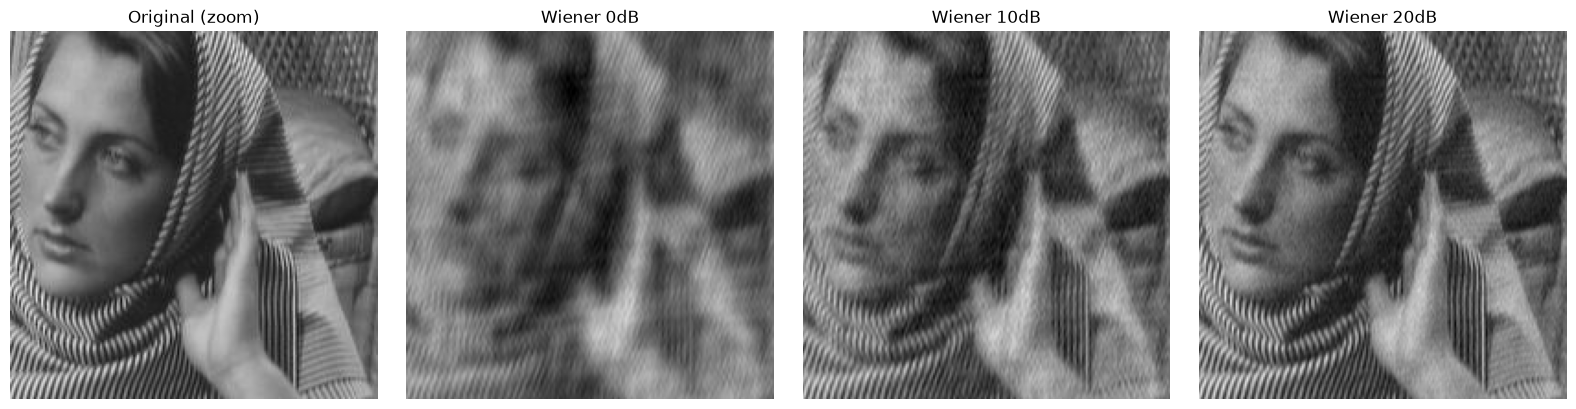

In [18]:
print('SNR noisy\tSNR Wiener\tgain')
for s in snrs:
    out = snr(x0, denoised[s])
    print(f'{snr(x0, noisy[s]):6.1f} dB\t{out:6.1f} dB\t{out - snr(x0, noisy[s]):+5.1f} dB')

show([noisy[s] for s in snrs] + [denoised[s] for s in snrs],
     [f'Noisy, {s} dB' for s in snrs] + [f'Wiener, {snr(x0, denoised[s]):.1f} dB' for s in snrs],
     cols=5, panel_size=3.5)

crop = (slice(40, 240), slice(270, 470))
show([x0[crop]] + [denoised[s][crop] for s in [0, 10, 20]],
     ['Original (zoom)'] + [f'Wiener {s}dB' for s in [0, 10, 20]], panel_size=4)

- We can see that the filter improves the SNR and its gain is bigger with more noise added ($+16$ dB at 0 dB, $+5$ dB at 20 dB). That is normal as with smaller noise, there is also less noise to remove.
- The stripes of the scarf are visible at 10 dB because their frequencies are kept as ots a repetitive pattern.But as the filter is the same for the whole image, these pattern repeats over the whole image.

### Gaussian filter comparaison

The Gaussian filter (the first filter of the Numerical Tour) is the most popular blur. For each SNR we keep the width $\mu$ that gives the best SNR, so the comparison is fair.

In [19]:
def gaussian_denoise(y, mu):
    """Gaussian blur of width mu (pixels), applied in the Fourier domain."""
    fy, fx = np.fft.fftfreq(y.shape[0])[:, None], np.fft.fftfreq(y.shape[1])[None, :]
    H = np.exp(-2 * np.pi**2 * mu**2 * (fx**2 + fy**2))
    return np.real(np.fft.ifft2(H * np.fft.fft2(y))), H

In [20]:
mus = np.linspace(0.1, 6, 60)
gauss, best_mu = {}, {}
for s in snrs:
    scores = [snr(x0, gaussian_denoise(noisy[s], mu)[0]) for mu in mus]
    best_mu[s] = mus[np.argmax(scores)]
    gauss[s] = gaussian_denoise(noisy[s], best_mu[s])[0]
    print(f'{s:2d} dB: best Gaussian (mu = {best_mu[s]:.1f} px) {snr(x0, gauss[s]):5.1f} dB   |   Wiener {snr(x0, denoised[s]):5.1f} dB')

 0 dB: best Gaussian (mu = 3.4 px)  15.1 dB   |   Wiener  15.9 dB
 5 dB: best Gaussian (mu = 2.4 px)  16.0 dB   |   Wiener  17.4 dB
10 dB: best Gaussian (mu = 1.1 px)  17.0 dB   |   Wiener  19.4 dB
15 dB: best Gaussian (mu = 0.6 px)  19.3 dB   |   Wiener  21.9 dB
20 dB: best Gaussian (mu = 0.4 px)  22.3 dB   |   Wiener  24.9 dB


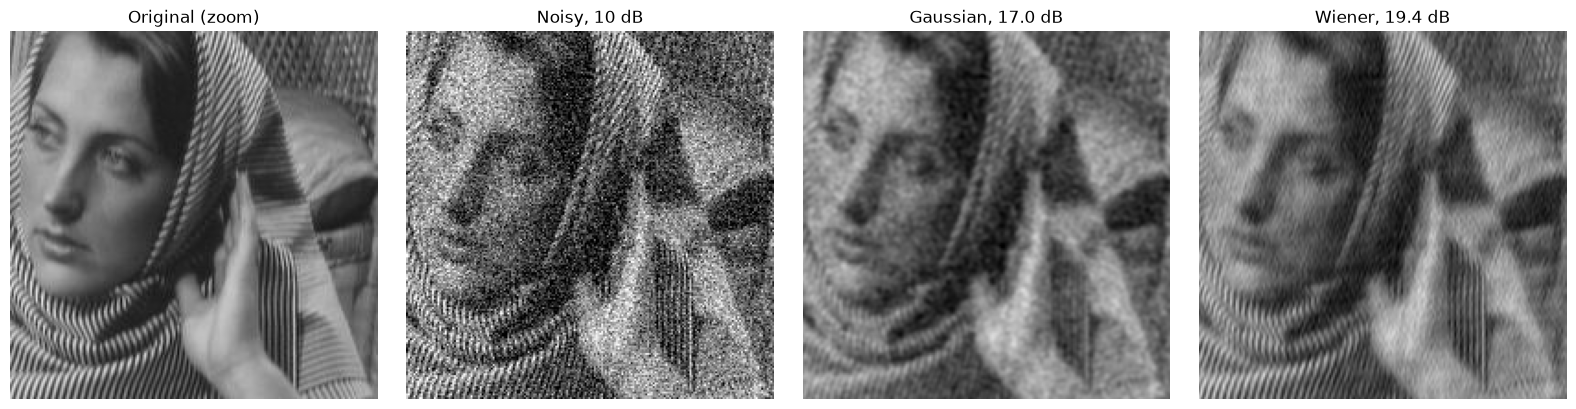

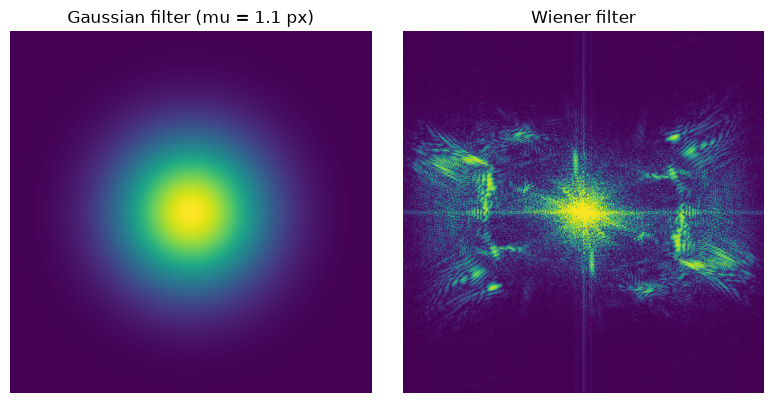

In [21]:
s = 10
show([x0[crop], noisy[s][crop], gauss[s][crop], denoised[s][crop]],
     ['Original (zoom)', f'Noisy, {s} dB', f'Gaussian, {snr(x0, gauss[s]):.1f} dB', f'Wiener, {snr(x0, denoised[s]):.1f} dB'], panel_size=4)
show([np.fft.fftshift(gaussian_denoise(noisy[s], best_mu[s])[1]), np.fft.fftshift(filters[s])],
     [f'Gaussian filter (mu = {best_mu[s]:.1f} px)', 'Wiener filter'], cmap='viridis', panel_size=4)

### No clean image

Normally we only have acces to $y$. Since image and noise are independent: 

$E[|\hat{y}(\nu)|^2] = E[|\hat{x}(\nu)|^2] + N\sigma^2$

so the image spectrum can be estimated by:

$$|\hat{x}(\nu)|^2 \approx \max\left(|\hat{y}(\nu)|^2 - N\sigma^2,\ 0\right)$$

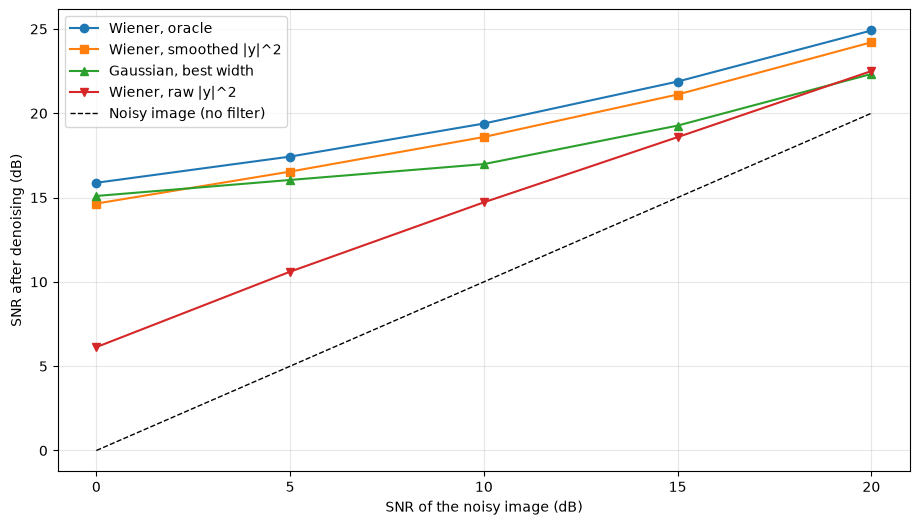

SNR in           Wiener, oracle   Wiener, smoothed |y|^2     Gaussian, best width        Wiener, raw |y|^2
  0 dB                  15.9 dB                  14.6 dB                  15.1 dB                   6.1 dB
  5 dB                  17.4 dB                  16.5 dB                  16.0 dB                  10.6 dB
 10 dB                  19.4 dB                  18.6 dB                  17.0 dB                  14.7 dB
 15 dB                  21.9 dB                  21.1 dB                  19.3 dB                  18.6 dB
 20 dB                  24.9 dB                  24.2 dB                  22.3 dB                  22.5 dB


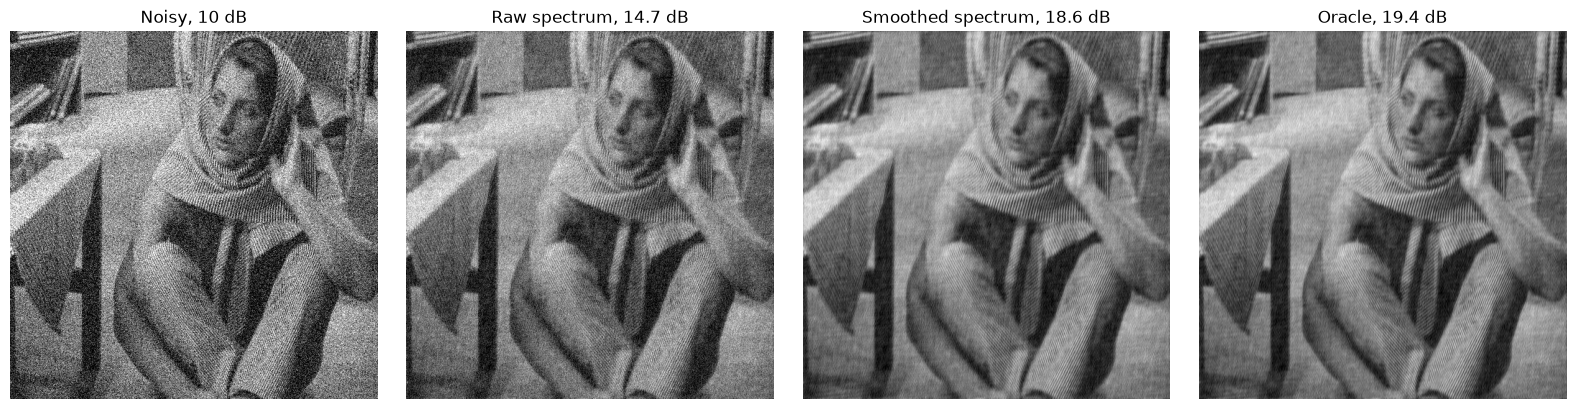

In [22]:
def wiener_from_noisy(y, sigma, smooth=9):
    """Wiener filter where the image spectrum is estimated from the noisy image itself."""
    Py = np.abs(np.fft.fft2(y))**2
    if smooth > 1:
        Py = uniform_filter(Py, smooth, mode='wrap')
    return wiener(y, np.maximum(Py - y.size * sigma**2, 0), sigma)[0]

est_raw = {s: wiener_from_noisy(noisy[s], sigmas[s], smooth=1) for s in snrs}
est_smooth = {s: wiener_from_noisy(noisy[s], sigmas[s]) for s in snrs}

results = {'Wiener, oracle': denoised, 'Wiener, smoothed |y|^2': est_smooth,
           'Gaussian, best width': gauss, 'Wiener, raw |y|^2': est_raw}
plt.figure(figsize=(11, 6))
for (label, res), marker in zip(results.items(), ['o', 's', '^', 'v']):
    plt.plot(snrs, [snr(x0, res[s]) for s in snrs], marker=marker, label=label)
plt.plot(snrs, snrs, 'k--', lw=1, label='Noisy image (no filter)')
plt.xticks(snrs)
plt.xlabel('SNR of the noisy image (dB)')
plt.ylabel('SNR after denoising (dB)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print('SNR in   ' + '   '.join(f'{k:>22}' for k in results))
for s in snrs:
    print(f'{s:3d} dB   ' + '   '.join(f'{snr(x0, res[s]):19.1f} dB' for res in results.values()))

s = 10
show([noisy[s], est_raw[s], est_smooth[s], denoised[s]],
     [f'Noisy, {s} dB', f'Raw spectrum, {snr(x0, est_raw[s]):.1f} dB',
      f'Smoothed spectrum, {snr(x0, est_smooth[s]):.1f} dB', f'Oracle, {snr(x0, denoised[s]):.1f} dB'], panel_size=4)

- with the raw spectrum we get bad results (6.1 dB at 0 dB, and a lot of noise is left). It's periodogram is very irregular, so at many frequencies with only noise, $|\hat{y}|^2$ is above $N\sigma^2$ by chance and the filter let the noise pass.
- Smoothed spectrum is 0.7 to 1.3 dB below the oracle at every SNR, without using the clean image. Averaging neighbour frequencies does for the image what Welch did for the noise files.

It beats the best Gaussian filter from 5 dB. At 0 dB the Gaussian is slightly better (15.1 against 14.6 dB), but its width was chosen with the clean image.

## Summary

| File | Slope (dB/decade) | Colour |
|---|---|---|
| noise1 | 0 | white |
| noise2 | $-10$ | pink |
| noise3 | $-9$ (low freq.) to $-1.6$ (high freq.) | pink + white ($0.705 \cdot \text{noise1} + 0.659 \cdot \text{noise2}$) |

- The periodogram is too irregular to read a spectrum. Welch gives a stable curve by averaging, and loses some frequency detail in exchange.
- The Wiener filter keeps each frequency according to how strong the image is compared to the noise. It gains from $+16$ dB (0 dB input) to $+5$ dB (20 dB input) and beats the best Gaussian blur.

## Limits
It is one filter for the whole image, so removing noise also means blur. And it needs the spectrum of the clean image; estimated from the noisy image, it only works if this estimate is smoothed.